# Módulo 3 — Neutralidade ao risco em tempo discreto

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** seções 4.1 a 4.4 e 4.7 do livro. A parte de tempo contínuo fica para o Módulo 4.

## O que você vai conseguir fazer ao final

1. Modelar incerteza e informação com objetos concretos: estados, eventos, álgebras e filtrações.
2. Calcular esperanças condicionais e testar se um processo é martingale.
3. Mudar de medida de probabilidade com a derivada de Radon-Nikodym.
4. Escrever carteiras, estratégias autofinanciadas e processos de ganho.
5. Enunciar e **entender a demonstração** do Teorema Fundamental, na versão de um período.
6. Precificar qualquer derivativo atingível e obter sua carteira replicante, inclusive com juros aleatórios.
7. Reconhecer um mercado incompleto e calcular o intervalo de preços sem arbitragem.

## Por que um módulo inteiro em mundo finito

Com um número finito de cenários, toda a teoria vira **soma e álgebra linear**. Cada definição pode ser verificada no computador, célula a célula. A intuição obtida aqui é a que levamos para o tempo contínuo, no próximo módulo, em que a matemática é bem mais pesada.

No Módulo 1 vimos a ideia em dois cenários: o preço vem do custo de replicação e existe uma probabilidade $q$ que o resume. Agora transformamos essa observação em teoria.

## 0. Preparação

In [1]:
from itertools import combinations, product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. Incerteza: estados, eventos e probabilidade

**Livro: §4.2, definições 1 a 4**

### 1.1 O ponto de partida: os estados

Fixamos um horizonte com datas $t = 0, 1, \dots, T$. Hoje não sabemos como o mundo estará em $T$, mas conhecemos a lista de possibilidades. Essa lista é o **espaço de estados** $\Omega$, e cada elemento $\omega$ é uma história completa.

Nossa economia-exemplo tem dois períodos, em cada um dos quais o índice sobe (`u`) ou desce (`d`):

$$\Omega = \{uu,\ ud,\ du,\ dd\}.$$

### 1.2 Eventos e álgebras

Um **evento** é um subconjunto de $\Omega$: por exemplo, "subiu no primeiro período" é $\{uu, ud\}$.

Nem todo evento precisa ser observável. Uma **álgebra** $\mathcal{F}$ é uma família de eventos que representa o que é observável. Ela precisa satisfazer três condições de bom senso:

1. $\Omega \in \mathcal{F}$: sempre sei que algo aconteceu.
2. Se $E \in \mathcal{F}$, então $E^c \in \mathcal{F}$: se consigo verificar que $E$ ocorreu, sei também quando não ocorreu.
3. Uniões finitas de eventos de $\mathcal{F}$ estão em $\mathcal{F}$.

**Toda álgebra num $\Omega$ finito vem de uma partição.** Basta pegar os menores eventos não vazios da álgebra, chamados **átomos**: eles dividem $\Omega$ sem sobreposição, e a álgebra é formada por todas as uniões possíveis deles. Por isso, no computador, representamos a informação pela partição.

Com $m$ átomos, cada um pode entrar ou não na união: são $2^m$ eventos.

### 1.3 Probabilidade e esperança

Uma **medida de probabilidade** atribui um número em $[0,1]$ a cada evento, de forma aditiva para eventos disjuntos e com $P(\Omega) = 1$. Num mundo finito, basta dar $P(\omega)$ em cada estado.

Duas medidas são **equivalentes** se concordam sobre o que é impossível: $P(E) = 0 \Leftrightarrow Q(E) = 0$. Elas podem discordar completamente das chances, mas não sobre o que pode ou não acontecer.

Uma **variável aleatória** é uma função de $\Omega$ nos números reais, e sua esperança é

$$\mathbb{E}^P[X] = \sum_{\omega\in\Omega} P(\omega)\,X(\omega).$$

### Laboratório 1.1 — Álgebras no computador

In [2]:
OMEGA = ["uu", "ud", "du", "dd"]


def algebra(particao):
    """Álgebra gerada por uma partição: todas as uniões possíveis de átomos."""
    atomos = [frozenset(a) for a in particao]
    saida = set()
    for k in range(len(atomos) + 1):
        for comb in combinations(atomos, k):
            saida.add(frozenset().union(*comb))
    return saida


def eh_algebra(F, omega):
    """Confere as três condições da definição de álgebra."""
    tudo = frozenset(omega)
    if tudo not in F:
        return False
    if any(tudo - E not in F for E in F):
        return False
    return all(A | B in F for A in F for B in F)


F0 = [["uu", "ud", "du", "dd"]]
F1 = [["uu", "ud"], ["du", "dd"]]
F2 = [["uu"], ["ud"], ["du"], ["dd"]]

linhas = []
for nome, p in [("F0: nada se sabe", F0), ("F1: conhece o 1º movimento", F1), ("F2: conhece tudo", F2)]:
    A = algebra(p)
    linhas.append({"Informação": nome, "Átomos": len(p), "Eventos na álgebra": len(A), "É álgebra?": eh_algebra(A, OMEGA)})
tabela(pd.DataFrame(linhas))
ok(all(l["É álgebra?"] and l["Eventos na álgebra"] == 2 ** l["Átomos"] for l in linhas), "cada partição gera uma álgebra com 2^m eventos")

falsa = {frozenset(), frozenset(OMEGA), frozenset({"uu"})}
ok(not eh_algebra(falsa, OMEGA), "uma família sem o complemento de {uu} não é álgebra")

,Informação,Átomos,Eventos na álgebra,É álgebra?
0,F0: nada se sabe,1,2,True
1,F1: conhece o 1º movimento,2,4,True
2,F2: conhece tudo,4,16,True


OK — cada partição gera uma álgebra com 2^m eventos
OK — uma família sem o complemento de {uu} não é álgebra


---
## 2. Informação ao longo do tempo

**Livro: §4.2, definições 5 a 9**

### 2.1 Filtração

A incerteza não se resolve de uma só vez. Uma **filtração** é uma sequência crescente de álgebras,

$$\mathcal{F}_0 \subseteq \mathcal{F}_1 \subseteq \dots \subseteq \mathcal{F}_T,$$

em que $\mathcal{F}_t$ representa o que se sabe na data $t$. Crescente significa que **ninguém esquece**. Em geral, $\mathcal{F}_0 = \{\emptyset, \Omega\}$ (nada se sabe) e $\mathcal{F}_T$ contém todos os eventos (tudo se sabe).

Em linguagem de partições: de uma data para a outra, os átomos **se dividem**.

### 2.2 Mensurabilidade e adaptação

Dizer que $X$ é **$\mathcal{F}_t$-mensurável** significa que $X$ é conhecida na data $t$. Na partição, a condição é concreta: **$X$ é constante em cada átomo de $\mathcal{F}_t$**.

Um processo $(S_t)$ é **adaptado** se $S_t$ é $\mathcal{F}_t$-mensurável para todo $t$: o preço de hoje é conhecido hoje.

### 2.3 Tempo de parada

Um **tempo de parada** é uma data aleatória $\tau$ em que a decisão de parar usa **apenas informação disponível até aquele momento**:

$$\{\tau \le t\} \in \mathcal{F}_t \quad \text{para todo } t.$$

"Vender na primeira vez que o índice cair" é um tempo de parada. "Vender no dia do máximo" não é, porque só se sabe qual foi o máximo depois. Esse conceito será central para as opções americanas no Módulo 9.

### Laboratório 2.1 — A economia-exemplo

Tomamos $S_0 = 100$, com alta de 20% ou queda de 20% por período, e juros de 5% por período. As probabilidades reais são $p = 70\%$ de alta, independentes.

,Estado,0,1,2
0,uu,"100,000","120,000","144,000"
1,ud,"100,000","120,000","96,000"
2,du,"100,000","80,000","96,000"
3,dd,"100,000","80,000","64,000"


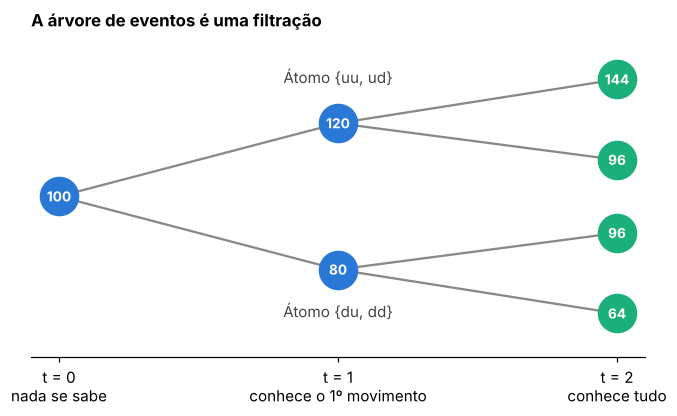

OK — o preço é adaptado à filtração
OK — o preço de t = 2 não é conhecido em t = 1


In [3]:
def particoes(T):
    """Partições da filtração natural de uma árvore binária de T períodos."""
    omega = ["".join(c) for c in product("ud", repeat=T)]
    saida = []
    for t in range(T + 1):
        grupos = {}
        for w in omega:
            grupos.setdefault(w[:t], []).append(w)
        saida.append(list(grupos.values()))
    return omega, saida


def arvore(T, S0, u, d):
    """Preços por trajetória: linhas são estados e colunas são datas."""
    omega, _ = particoes(T)
    S = pd.DataFrame(index=omega, columns=range(T + 1), dtype=float)
    for w in omega:
        v = S0
        S.loc[w, 0] = v
        for t, c in enumerate(w, start=1):
            v *= u if c == "u" else d
            S.loc[w, t] = v
    return S


def medida(omega, p):
    return pd.Series({w: np.prod([p if c == "u" else 1 - p for c in w]) for w in omega})


def mensuravel(X, particao):
    return all(np.ptp(X.loc[a].values) < 1e-12 for a in particao)


T, S0, u, d, r, p = 2, 100.0, 1.2, 0.8, 0.05, 0.7
omega, filtracao = particoes(T)
S = arvore(T, S0, u, d)
P = medida(omega, p)
tabela(S.reset_index(names="Estado"))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
nos = {"": (0, 0), "u": (1, 1), "d": (1, -1), "uu": (2, 1.6), "ud": (2, 0.5), "du": (2, -0.5), "dd": (2, -1.6)}
for pai, (x0, y0) in nos.items():
    for m in "ud":
        filho = pai + m
        if filho in nos:
            ax.plot([x0, nos[filho][0]], [y0, nos[filho][1]], color=CINZA, lw=1.5, zorder=1)
for no, (x, y) in nos.items():
    t = len(no)
    w = (no + "uu")[:T]
    ax.scatter([x], [y], s=620, color=AZUL if t < 2 else VERDE, zorder=2)
    ax.text(x, y, f"{S.loc[w, t]:.0f}", ha="center", va="center", color="white", fontweight="bold", fontsize=9, zorder=3)
ax.text(1, 1.55, "Átomo {uu, ud}", ha="center", color="#444440")
ax.text(1, -1.65, "Átomo {du, dd}", ha="center", color="#444440")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["t = 0\nnada se sabe", "t = 1\nconhece o 1º movimento", "t = 2\nconhece tudo"])
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_ylim(-2.2, 2.2)
ax.set_title("A árvore de eventos é uma filtração")
plt.show()

ok(mensuravel(S[1], filtracao[1]) and mensuravel(S[2], filtracao[2]), "o preço é adaptado à filtração")
ok(not mensuravel(S[2], filtracao[1]), "o preço de t = 2 não é conhecido em t = 1")

### Laboratório 2.2 — O preço de hoje não basta como informação

Em nossa árvore, $S_2(ud) = S_2(du) = 96$. Se alguém só observar $S_2$, não saberá qual caminho ocorreu: a álgebra gerada por $S_2$ tem 3 átomos, e não 4. Já observando todo o histórico $(S_1, S_2)$, todos os estados se separam.

É por isso que produtos dependentes da trajetória exigem controlar o caminho, e não só o preço final.

In [4]:
def particao_gerada(serie):
    """Partição da álgebra gerada por uma variável (ou tupla de variáveis)."""
    grupos = {}
    for w, v in serie.items():
        grupos.setdefault(v if isinstance(v, tuple) else round(float(v), 9), []).append(w)
    return list(grupos.values())


so_final = particao_gerada(S[2])
historico = pd.Series({w: (round(S.loc[w, 1], 9), round(S.loc[w, 2], 9)) for w in omega})
com_historico = particao_gerada(historico)

print("Só o preço final:", so_final)
print("Todo o histórico:", com_historico)
ok(len(so_final) == 3 and len(com_historico) == 4, "o histórico contém mais informação do que o preço final")


def eh_tempo_de_parada(tau, filt):
    """Testa se {tau <= t} é união de átomos de F_t para todo t."""
    for t, part in enumerate(filt):
        evento = set(tau.index[tau <= t])
        for a in part:
            if not (set(a) <= evento or not (set(a) & evento)):
                return False
    return True


primeira_queda = pd.Series({w: (w.index("d") + 1 if "d" in w else T) for w in omega})
dia_do_maximo = pd.Series({w: int(np.argmax(S.loc[w].values)) for w in omega})
tabela(pd.DataFrame({"Primeira queda": primeira_queda, "Dia do máximo": dia_do_maximo}).reset_index(names="Estado"))
ok(eh_tempo_de_parada(primeira_queda, filtracao), "'primeira queda' é um tempo de parada")
ok(not eh_tempo_de_parada(dia_do_maximo, filtracao), "'dia do máximo' exige olhar o futuro: não é tempo de parada")

Só o preço final: [['uu'], ['ud', 'du'], ['dd']]
Todo o histórico: [['uu'], ['ud'], ['du'], ['dd']]
OK — o histórico contém mais informação do que o preço final


,Estado,Primeira queda,Dia do máximo
0,uu,2,2
1,ud,2,1
2,du,1,0
3,dd,1,0


OK — 'primeira queda' é um tempo de parada
OK — 'dia do máximo' exige olhar o futuro: não é tempo de parada


---
## 3. Esperança condicional e martingales

**Livro: §4.2, definições 10 e 11**

### 3.1 Esperança condicional, passo a passo

Na data $t$ já sabemos em que átomo estamos, e a melhor previsão usa apenas os estados daquele átomo, com as probabilidades reponderadas. Para cada átomo $A$ de $\mathcal{F}_t$:

$$\mathbb{E}^P_t[X]\,(\omega) = \frac{\sum_{\eta\in A} P(\eta)\,X(\eta)}{P(A)} \qquad \text{para } \omega\in A.$$

Note que **a esperança condicional é, ela própria, uma variável aleatória**: uma média diferente para cada átomo.

A definição formal do livro exige duas propriedades:

1. $\mathbb{E}^P_t[X]$ é $\mathcal{F}_t$-mensurável (só depende do que se sabe em $t$);
2. para todo evento $E \in \mathcal{F}_t$: $\ \mathbb{E}^P\big[\mathbb{E}^P_t[X]\,\mathbf{1}_E\big] = \mathbb{E}^P[X\,\mathbf{1}_E]$ (o valor médio em cada evento conhecido é preservado).

Dessas decorre a **lei das esperanças iteradas**: para $s \le t$, $\mathbb{E}_s\big[\mathbb{E}_t[X]\big] = \mathbb{E}_s[X]$. Em palavras: minha previsão de hoje sobre minha previsão de amanhã é a minha previsão de hoje.

### 3.2 Martingale

Um processo adaptado é um **martingale** sob $Q$ se

$$\mathbb{E}^Q_t[S_{t+s}] = S_t.$$

É o modelo matemático do jogo justo: a melhor previsão para qualquer data futura é o valor atual.

**Basta verificar um passo.** Se $\mathbb{E}_t[S_{t+1}] = S_t$ para todo $t$, a lei das esperanças iteradas dá $\mathbb{E}_t[S_{t+2}] = \mathbb{E}_t\big[\mathbb{E}_{t+1}[S_{t+2}]\big] = \mathbb{E}_t[S_{t+1}] = S_t$, e assim por diante.

### Laboratório 3.1 — Conferindo definições

Testamos o preço **descontado** $\tilde S_t = S_t/(1+r)^t$ sob duas medidas: a real ($p = 70\%$) e aquela em que $q$ é escolhido para zerar o ganho esperado do preço descontado:

$$q = \frac{(1+r) - d}{u - d}.$$

In [5]:
def E_cond(X, particao, prob):
    """Esperança condicional de X dada a informação da partição, sob a medida prob."""
    Y = pd.Series(index=X.index, dtype=float)
    for a in particao:
        Y.loc[a] = float((X.loc[a] * prob.loc[a]).sum() / prob.loc[a].sum())
    return Y


def eh_martingale(X, filt, prob):
    """X é DataFrame com colunas t. Testa o passo de um período em todas as datas."""
    return all(np.allclose(E_cond(X[t + 1], filt[t], prob), X[t]) for t in range(len(filt) - 1))


B = pd.DataFrame({t: (1 + r) ** t for t in range(T + 1)}, index=omega)
S_desc = S / B
q = (1 + r - d) / (u - d)
Q = medida(omega, q)

print("q =", f3(q), "| p =", f3(p))
X = S[2]
EX = E_cond(X, filtracao[1], P)
ok(mensuravel(EX, filtracao[1]), "propriedade 1: a esperança condicional é mensurável em F_1")
ok(all(abs(float((EX[list(E)] * P[list(E)]).sum()) - float((X[list(E)] * P[list(E)]).sum())) < 1e-10 for E in algebra(filtracao[1]) if E), "propriedade 2: as médias são preservadas em todo evento de F_1")
ok(abs(float((EX * P).sum()) - float((X * P).sum())) < 1e-10, "lei das esperanças iteradas")
ok(eh_martingale(S_desc, filtracao, Q), "o preço descontado é martingale sob Q")
ok(not eh_martingale(S_desc, filtracao, P), "o preço descontado não é martingale sob P")

q = 0,625 | p = 0,700
OK — propriedade 1: a esperança condicional é mensurável em F_1
OK — propriedade 2: as médias são preservadas em todo evento de F_1
OK — lei das esperanças iteradas
OK — o preço descontado é martingale sob Q
OK — o preço descontado não é martingale sob P


### 3.3 Trocando de medida: a derivada de Radon-Nikodym

Se $Q$ é equivalente a $P$, definimos, estado a estado,

$$L(\omega) = \frac{Q(\omega)}{P(\omega)}.$$

Uma esperança sob $Q$ pode, então, ser calculada sob $P$. Basta multiplicar e dividir por $P(\omega)$:

$$\mathbb{E}^Q[X] = \sum_\omega Q(\omega)X(\omega) = \sum_\omega P(\omega)\frac{Q(\omega)}{P(\omega)}X(\omega) = \mathbb{E}^P[L\,X].$$

Duas consequências que o livro não desenvolve, mas que usaremos no próximo módulo para o teorema de Girsanov:

**Processo de densidade.** $L_t = \mathbb{E}^P_t[L]$ é um martingale sob $P$, com $L_0 = 1$.

**Fórmula de Bayes.** Para esperanças condicionais, não basta multiplicar por $L$; é preciso normalizar:

$$\mathbb{E}^Q_t[X] = \frac{\mathbb{E}^P_t[L\,X]}{L_t}.$$

Para ver o porquê, fixe um átomo $A$ de $\mathcal{F}_t$. Do lado esquerdo, a definição dá $\sum_A Q X / Q(A)$. Do lado direito, o numerador é $\sum_A P L X / P(A) = \sum_A Q X / P(A)$, e o denominador é $L_t = Q(A)/P(A)$. Dividindo, $P(A)$ se cancela e os dois lados coincidem.

In [6]:
L = Q / P
Lt = pd.DataFrame({t: E_cond(L, filtracao[t], P) for t in range(T + 1)})
tabela(pd.DataFrame({"P": P, "Q": Q, "L = Q/P": L}).reset_index(names="Estado"))

ok(abs(float((Q * S[2]).sum()) - float((P * L * S[2]).sum())) < 1e-10, "E^Q[X] = E^P[L X]")
ok(eh_martingale(Lt, filtracao, P) and abs(float(Lt[0].iloc[0]) - 1) < 1e-12, "L_t é martingale sob P e começa em 1")
bayes = E_cond(L * S[2], filtracao[1], P) / Lt[1]
ok(np.allclose(bayes, E_cond(S[2], filtracao[1], Q)), "fórmula de Bayes para esperança condicional")

,Estado,P,Q,L = Q/P
0,uu,"0,490","0,391","0,797"
1,ud,"0,210","0,234","1,116"
2,du,"0,210","0,234","1,116"
3,dd,"0,090","0,141","1,562"


OK — E^Q[X] = E^P[L X]
OK — L_t é martingale sob P e começa em 1
OK — fórmula de Bayes para esperança condicional


---
## 4. O mercado: carteiras e estratégias

**Livro: §4.3**

### 4.1 Ativos

O mercado tem $K+1$ ativos. O ativo 0 é o **título** (*bond*), com $S^0_0 = 1$, que serve de **numerário**. Ele é sem risco no sentido de que $S^0_t$ é conhecido já em $t-1$. O **fator de desconto** é $\beta_t = 1/S^0_t$.

Isso inclui juros aleatórios: o juro do próximo período é desconhecido hoje, mas é conhecido no início do período. Veremos um exemplo na Seção 8.

### 4.2 Estratégia de negociação

Uma **estratégia** é um processo $\phi_t = (\phi^0_t, \dots, \phi^K_t)$ com a quantidade de cada ativo no período $(t-1, t]$. Ela precisa ser **previsível**: $\phi_t$ é $\mathcal{F}_{t-1}$-mensurável, ou seja, a carteira do período é escolhida **antes** de se conhecer o movimento do período.

O valor da estratégia é $V_t = \phi_t \cdot S_t$ e o ganho acumulado é

$$G_t = \sum_{i=1}^{t}\phi_i\cdot(S_i - S_{i-1}).$$

### 4.3 Autofinanciamento

Na data $t$, a carteira velha vale $\phi_t\cdot S_t$. Ao montar a nova, sem entrada nem saída de recursos, a condição é

$$\phi_t\cdot S_t = \phi_{t+1}\cdot S_t.$$

Isso equivale a $V_t = V_0 + G_t$: **a riqueza só muda por ganhos de mercado**.

### 4.4 O lema que sustenta toda a teoria

Vamos descontar, com $\tilde S_t = \beta_t S_t$ e $\tilde V_t = \beta_t V_t$. Multiplicando a condição de autofinanciamento por $\beta_t$, ela continua válida em termos descontados: $\phi_t\cdot\tilde S_t = \phi_{t+1}\cdot\tilde S_t$. Usando isso na variação de um período:

$$\tilde V_{t+1} - \tilde V_t = \phi_{t+1}\cdot\tilde S_{t+1} - \phi_{t}\cdot\tilde S_{t} = \phi_{t+1}\cdot\tilde S_{t+1} - \phi_{t+1}\cdot\tilde S_{t} = \phi_{t+1}\cdot(\tilde S_{t+1} - \tilde S_t).$$

Somando no tempo:

$$\tilde V_T = \tilde V_0 + \sum_{t=1}^{T}\phi_t\cdot\big(\tilde S_t - \tilde S_{t-1}\big).$$

Agora suponha que $\tilde S$ é martingale sob $Q$. Como $\phi_t$ é previsível, sai da esperança condicional:

$$\mathbb{E}^Q_{t-1}\big[\phi_t\cdot(\tilde S_t - \tilde S_{t-1})\big] = \phi_t\cdot\mathbb{E}^Q_{t-1}\big[\tilde S_t - \tilde S_{t-1}\big] = 0.$$

Conclusão: **o valor descontado de qualquer estratégia autofinanciada previsível também é martingale sob $Q$**. Uma aposta justa, com quantidade escolhida de antemão, continua justa, seja qual for a regra.

> **Errata do livro:** na prova da Proposição 1 (§4.7.2), a soma aparece com o termo $\phi_t\cdot(\beta_t S_t - \beta_{t+1}S_{t+1})$, para $t = 2, \dots, T$. O índice correto é o da expressão acima: $\phi_t\cdot(\beta_t S_t - \beta_{t-1}S_{t-1})$. Da forma impressa, a soma usaria $S_{T+1}$, que não existe.

### Laboratório 4.1 — Não dá para vencer um jogo justo, a menos que se olhe o futuro

Simulamos um martingale simples, com passos de $\pm 1$ e chances iguais, em 20 períodos. Comparamos estratégias previsíveis com uma que "espia" o movimento do período.

,Estratégia,Previsível?,Ganho médio final,Erro-padrão
0,Comprar e manter,True,"-0,007","0,007"
1,Seguir o último movimento,True,"0,001","0,007"
2,Apostar contra o último movimento,True,"-0,001","0,007"
3,Dobrar após perda (limite 64),True,"0,055","0,059"
4,Espiar o movimento do período,False,"20,000","0,000"


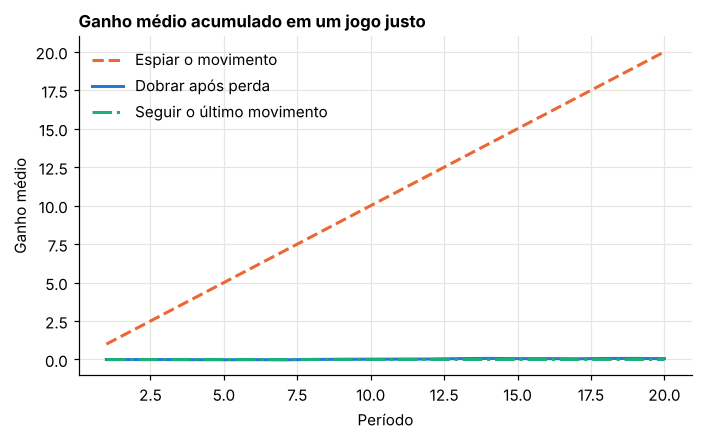

OK — nenhuma regra previsível altera o ganho médio de um jogo justo
OK — sem previsibilidade, o jogo deixa de ser justo


In [7]:
rng = np.random.default_rng(403)
periodos, cenarios = 20, 400_000
dX = rng.choice([-1.0, 1.0], size=(cenarios, periodos))


def ganhos(fi):
    return np.cumsum(fi * dX, axis=1)


constante = np.ones_like(dX)
momento = np.hstack([np.ones((cenarios, 1)), np.sign(dX[:, :-1])])
reversao = -momento

dobrar = np.ones_like(dX)
for t in range(1, periodos):
    perdeu = dX[:, t - 1] < 0
    dobrar[:, t] = np.where(perdeu, np.minimum(dobrar[:, t - 1] * 2, 64.0), 1.0)

espiando = np.sign(dX)

estrategias = {
    "Comprar e manter": constante,
    "Seguir o último movimento": momento,
    "Apostar contra o último movimento": reversao,
    "Dobrar após perda (limite 64)": dobrar,
    "Espiar o movimento do período": espiando,
}

linhas, curvas = [], {}
for nome, fi in estrategias.items():
    g = ganhos(fi)
    curvas[nome] = g.mean(axis=0)
    gf = g[:, -1]
    linhas.append({"Estratégia": nome, "Previsível?": nome != "Espiar o movimento do período", "Ganho médio final": gf.mean(), "Erro-padrão": gf.std(ddof=1) / np.sqrt(cenarios)})
res = pd.DataFrame(linhas)
tabela(res)

fig, ax = plt.subplots()
ax.plot(range(1, periodos + 1), curvas["Espiar o movimento do período"], color=LARANJA, ls="--", label="Espiar o movimento")
ax.plot(range(1, periodos + 1), curvas["Dobrar após perda (limite 64)"], color=AZUL, label="Dobrar após perda")
ax.plot(range(1, periodos + 1), curvas["Seguir o último movimento"], color=VERDE, ls="-.", label="Seguir o último movimento")
ax.set_title("Ganho médio acumulado em um jogo justo")
ax.set_xlabel("Período")
ax.set_ylabel("Ganho médio")
ax.legend()
plt.show()

prev = res[res["Previsível?"]]
ok((prev["Ganho médio final"].abs() < 4 * prev["Erro-padrão"]).all(), "nenhuma regra previsível altera o ganho médio de um jogo justo")
ok(res.loc[~res["Previsível?"], "Ganho médio final"].iloc[0] > 19.9, "sem previsibilidade, o jogo deixa de ser justo")

**Observação.** A estratégia de dobrar a aposta aparenta ganhar quase sempre, mas com limite de exposição o ganho médio é zero: os muitos ganhos pequenos são exatamente compensados por raras perdas grandes. Sem limite, surgem problemas em tempo contínuo, e a noção de estratégia admissível no Módulo 4 serve para excluí-los.

---
## 5. Arbitragem

**Livro: §4.4, definições 21 a 26**

### 5.1 Direitos contingentes

Um **direito contingente** é um pagamento $A_T(\omega) \ge 0$ em $T$, que depende do estado. Opções são exemplos. O direito é **atingível** se existe uma estratégia autofinanciada com $V_T = A_T$: esse direito é **redundante** e o preço dele deve ser $V_0$.

### 5.2 O que é arbitragem

Arbitragem é um almoço grátis: uma estratégia autofinanciada com

$$V_0 = 0, \qquad V_T \ge 0 \text{ em todos os estados}, \qquad \mathbb{E}^P[V_T] > 0.$$

Não custa nada, nunca dá prejuízo e tem chance de lucro. Note que as probabilidades reais só importam para dizer **o que é possível**: basta que $P(\omega) > 0$.

> **Errata do livro, que afeta o entendimento.** O livro define estratégia admissível (Def. 19) como aquela com valor limitado inferiormente, $V_t \ge -\alpha$, e arbitragem (Def. 25) como estratégia admissível com $V_0 = 0$ e $\mathbb{E}[V_T] > 0$. Num mundo finito, **toda** estratégia é limitada inferiormente. Pela letra do livro, comprar o índice com dinheiro emprestado seria arbitragem sempre que o retorno esperado superasse a taxa de juros, o que contradiz o próprio Teorema 1. No artigo original de Harrison e Pliska, admissível significa $V_t \ge 0$, e é isso que faz a definição funcionar. A prova do Lema 1, no livro, já parte de $V_t \ge 0$.

### Laboratório 5.1 — A definição do livro, ao pé da letra

Em nossa economia, sabemos que existe medida martingale. Portanto, não pode haver arbitragem. Mas vejamos a estratégia "comprar o índice com dinheiro emprestado".

In [8]:
fi_S, fi_B = 1.0, -100.0
V0 = fi_S * S0 + fi_B * 1.0
VT = fi_S * S[2] + fi_B * B[2]

tabela(pd.DataFrame({"Valor final": VT, "Prob. real": P}).reset_index(names="Estado"))
print("Custo inicial:", f3(V0), "| Valor esperado final:", f3(float((VT * P).sum())), "| Pior caso:", f3(float(VT.min())))

ok(V0 == 0 and (VT * P).sum() > 0 and VT.min() > -np.inf, "satisfaz a Definição 25 como impressa")
ok(VT.min() < 0, "mas pode dar prejuízo: não é arbitragem")
ok(abs(float((VT / B[2] * Q).sum())) < 1e-10, "e sob Q seu valor esperado descontado é zero")

,Estado,Valor final,Prob. real
0,uu,"33,750","0,490"
1,ud,"-14,250","0,210"
2,du,"-14,250","0,210"
3,dd,"-46,250","0,090"


Custo inicial: 0,000 | Valor esperado final: 6,390 | Pior caso: -46,250
OK — satisfaz a Definição 25 como impressa
OK — mas pode dar prejuízo: não é arbitragem
OK — e sob Q seu valor esperado descontado é zero


### 5.3 Arbitragem fraca: o Lema 1 com números

Pode haver uma estratégia com $V_0 = 0$ e $V_T \ge 0$ que, no meio do caminho, passe por valor **negativo**. A definição de Harrison e Pliska exige $V_t \ge 0$ em todas as datas, e o livro chama essa versão mais frouxa de **arbitragem fraca**. O Lema 1 diz que não há diferença essencial: de uma arbitragem fraca sempre se extrai uma arbitragem no sentido forte.

**A ideia da prova.** Olhe para o último instante em que o valor fica negativo, e o evento em que isso ocorre. Não faça nada até lá. Nesse instante e nesse evento, comece a estratégia, pois o déficit já não é mais carregado: o valor inicial passa a ser zero e o resultado final só melhora.

Exemplo com $r = 0$. O índice começa em 100 e vai a 110 ou 90. Em $d$, porém, os dois sucessores são 95 e 92, ambos acima de 90: há uma oportunidade naquele nó.

> **Errata menor:** na prova do Lema 1, em "$\psi_u(\omega) \equiv 0$ if $u < t$ as well as $\omega \notin E$", deveria ser $u > t$.

In [9]:
est = ["uu", "ud", "du", "dd"]
S_lema = pd.DataFrame({0: 100.0, 1: [110.0, 110.0, 90.0, 90.0], 2: [120.0, 100.0, 95.0, 92.0]}, index=est)

# Estratégia fraca: comprar 1 unidade a crédito; em d, comprar mais 4; em u, zerar.
fi_S1 = pd.Series(1.0, index=est)
fi_B1 = pd.Series(-100.0, index=est)
fi_S2 = pd.Series({"uu": 0.0, "ud": 0.0, "du": 5.0, "dd": 5.0})
fi_B2 = fi_B1 + (fi_S1 - fi_S2) * S_lema[1]

V1 = fi_S1 * S_lema[1] + fi_B1
V2 = fi_S2 * S_lema[2] + fi_B2

# Estratégia corrigida: nada até t=1; em d, entra com a mesma posição, mais o déficit em caixa.
a = V1["dd"]
psi_S2 = pd.Series({"uu": 0.0, "ud": 0.0, "du": 5.0, "dd": 5.0})
psi_B2 = pd.Series({"uu": 0.0, "ud": 0.0, "du": fi_B2["du"] - a, "dd": fi_B2["dd"] - a})
W1 = pd.Series({"uu": 0.0, "ud": 0.0, "du": float(psi_S2["du"] * 90.0 + psi_B2["du"]), "dd": float(psi_S2["dd"] * 90.0 + psi_B2["dd"])})
W2 = psi_S2 * S_lema[2] + psi_B2

tabela(pd.DataFrame({"V1 fraca": V1, "V2 fraca": V2, "V1 corrigida": W1, "V2 corrigida": W2}).reset_index(names="Estado"))
ok(V1.min() < 0 and V2.min() >= 0 and V2.max() > 0, "a estratégia fraca passa por valor negativo, mas termina não negativa")
ok(W1.abs().max() < 1e-9 and W2.min() >= 0 and W2.max() > 0, "a estratégia corrigida é arbitragem em sentido forte")

,Estado,V1 fraca,V2 fraca,V1 corrigida,V2 corrigida
0,uu,"10,000","10,000","0,000","0,000"
1,ud,"10,000","10,000","0,000","0,000"
2,du,"-10,000","15,000","0,000","25,000"
3,dd,"-10,000","0,000","0,000","10,000"


OK — a estratégia fraca passa por valor negativo, mas termina não negativa
OK — a estratégia corrigida é arbitragem em sentido forte


---
## 6. O Teorema Fundamental

**Livro: §4.4, Teorema 1 e §4.7.3**

### Enunciado

No modelo de mercado discreto, são equivalentes:

1. Não há oportunidades de arbitragem.
2. Existe uma medida $Q$, equivalente a $P$, sob a qual os preços descontados são martingales.
3. Existe um sistema de preços lineares consistente com o mercado.

### A versão de um período, passo a passo

Considere $n$ ativos e $m$ estados. O ativo $j$ custa $p_j$ hoje e paga $D_{\omega j}$ no estado $\omega$. A matriz $D$ tem $m$ linhas e $n$ colunas. Uma carteira $\theta$ custa $p\cdot\theta$ e paga $D\theta$.

**Definição de preços de estado.** Um vetor $\psi \in \mathbb{R}^m$, com todos os componentes positivos, tal que

$$p = D^\top\psi, \quad\text{isto é,}\quad p_j = \sum_\omega \psi_\omega D_{\omega j}.$$

$\psi_\omega$ é o **preço hoje de receber 1 no estado $\omega$** (título de Arrow-Debreu).

**Parte fácil: preços de estado eliminam arbitragem.** Se $D\theta \ge 0$ e pelo menos um componente é positivo, e $\psi$ é estritamente positivo, então

$$p\cdot\theta = (D^\top\psi)\cdot\theta = \psi\cdot D\theta > 0.$$

Ou seja, uma carteira com pagamento não negativo e não nulo **tem custo positivo**. Não há almoço grátis.

**Parte difícil: sem arbitragem existem preços de estado.** Aqui está a ideia geométrica.

**Passo 1.** Cada carteira gera o vetor $\big(-p\cdot\theta,\ D\theta\big)$ em $\mathbb{R}^{1+m}$: fluxo de caixa hoje e em cada estado. O conjunto desses vetores é um **subespaço linear** $M$.

**Passo 2.** Arbitragem significa que $M$ toca o octante positivo $\mathbb{R}^{1+m}_+$ em algum ponto diferente da origem.

**Passo 3.** Sem arbitragem, $M$ e o octante só se encontram na origem. Pelo **teorema do hiperplano separador**, existe um vetor $(\psi_0, \psi)$ estritamente positivo e **ortogonal a $M$**.

**Passo 4.** Ortogonal a $M$ significa, para todo $\theta$:

$$-\psi_0\,p\cdot\theta + \psi\cdot D\theta = 0.$$

Como vale para todo $\theta$, temos $\psi_0\,p = D^\top\psi$. Normalizando por $\psi_0$, chegamos a $p = D^\top\psi$.

### De preços de estado a medida martingale

Seja o título, que custa 1 e paga $1+r$ em todos os estados. Aplicando $p = D^\top\psi$:

$$1 = (1+r)\sum_\omega\psi_\omega.$$

Logo, a soma dos $\psi_\omega$ é o fator de desconto. Defina

$$Q(\omega) = (1+r)\,\psi_\omega.$$

São números positivos que somam 1: uma probabilidade. Para qualquer ativo,

$$p_j = \sum_\omega\psi_\omega D_{\omega j} = \frac{1}{1+r}\sum_\omega Q(\omega) D_{\omega j} = \frac{\mathbb{E}^Q[D_j]}{1+r}.$$

**A probabilidade neutra ao risco é apenas o preço de estado normalizado.** Essa é a relação da Proposição 1 do livro entre sistema de preços e medida martingale.

### A geometria com dois estados

Com um ativo arriscado e dois estados, o ganho descontado de uma carteira com $\theta$ unidades é $\theta\,(\Delta\tilde S_u, \Delta\tilde S_d)$: todas as carteiras formam uma **reta pela origem**.

- Se a reta atravessa os quadrantes sem entrar no positivo, não há arbitragem, e a normal à reta dá $(q, 1-q)$.
- Se a reta entra no quadrante positivo, há arbitragem, e nenhuma normal tem componentes positivos.

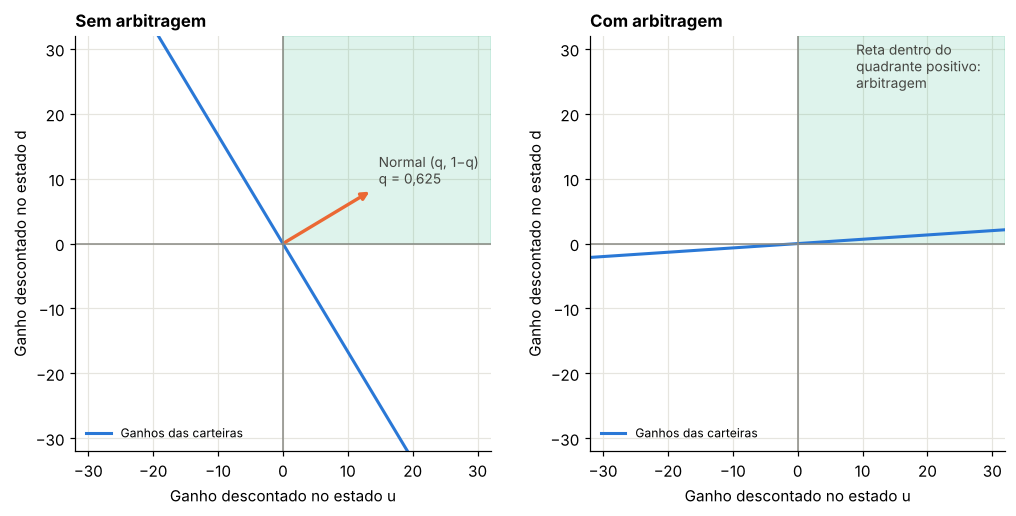

In [10]:
def painel(ax, Su, Sd, r, titulo):
    du_, dd_ = Su / (1 + r) - 100, Sd / (1 + r) - 100
    lim = 32
    ax.axhspan(0, lim, xmin=0.5, xmax=1, color=VERDE, alpha=0.14)
    esc = 2 * lim / max(abs(du_), abs(dd_))
    ax.plot([-esc * du_, esc * du_], [-esc * dd_, esc * dd_], color=AZUL, label="Ganhos das carteiras")
    ax.axhline(0, color=CINZA, lw=1)
    ax.axvline(0, color=CINZA, lw=1)
    if du_ * dd_ < 0:
        q = -dd_ / (du_ - dd_)
        ax.annotate("", xy=(22 * q, 22 * (1 - q)), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=LARANJA, lw=2.2))
        ax.text(22 * q + 1, 22 * (1 - q) + 1, f"Normal (q, 1−q)\nq = {f3(q)}", color="#444440", fontsize=9)
    else:
        ax.text(9, 24, "Reta dentro do\nquadrante positivo:\narbitragem", color="#444440", fontsize=9)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_title(titulo)
    ax.set_xlabel("Ganho descontado no estado u")
    ax.set_ylabel("Ganho descontado no estado d")
    ax.legend(loc="lower left", fontsize=8)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 4.6))
painel(a1, 120.0, 80.0, 0.05, "Sem arbitragem")
painel(a2, 120.0, 106.0, 0.05, "Com arbitragem")
plt.tight_layout()
plt.show()

### Laboratório 6.1 — Teste de força do teorema em mercados aleatórios

Sorteamos centenas de mercados, com números aleatórios de ativos e estados, e para cada um respondemos duas perguntas **de forma independente**, por programação linear:

- **Existe arbitragem?** Procuramos $\theta$ limitado com $D\theta \ge 0$, $p\cdot\theta \le 0$ e benefício positivo.
- **Existem preços de estado positivos?** Procuramos $\psi$ com $D^\top\psi = p$ e o maior piso $\varepsilon$ possível.

O teorema diz que **exatamente uma** das respostas é sim, em todos os mercados.

In [11]:
def achar_arbitragem(D, p):
    """Maximiza o benefício de uma carteira limitada com Dθ >= 0 e p·θ <= 0."""
    m, n = D.shape
    A_ub = np.vstack([-D, p])
    b_ub = np.zeros(m + 1)
    c = -(D.sum(axis=0) - p)
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=[(-1, 1)] * n, method="highs")
    return -res.fun, res.x


def achar_precos_estado(D, p):
    """Maximiza o piso ε de um vetor ψ com D'ψ = p."""
    m, n = D.shape
    c = np.zeros(m + 1)
    c[-1] = -1.0
    A_eq = np.hstack([D.T, np.zeros((n, 1))])
    A_ub = np.hstack([-np.eye(m), np.ones((m, 1))])
    res = linprog(c, A_ub=A_ub, b_ub=np.zeros(m), A_eq=A_eq, b_eq=p, bounds=[(None, None)] * m + [(None, 1.0)], method="highs")
    if res.status != 0:
        return -np.inf, None
    return res.x[-1], res.x[:-1]


rng = np.random.default_rng(406)
tol = 1e-8
tot = {"sem arbitragem": 0, "com arbitragem": 0, "contradições": 0}
for i in range(800):
    m, n = rng.integers(2, 7), rng.integers(1, 6)
    D = rng.uniform(0.0, 3.0, (m, n))
    if i % 2 == 0:
        p = D.T @ rng.uniform(0.05, 1.0, m)
    else:
        p = rng.uniform(0.0, 3.0, n)
    benef, _ = achar_arbitragem(D, p)
    eps, _ = achar_precos_estado(D, p)
    arb, psi = benef > tol, eps > tol
    if arb == psi:
        tot["contradições"] += 1
    tot["com arbitragem" if arb else "sem arbitragem"] += 1

print(tot)
ok(tot["contradições"] == 0, "em todos os mercados sorteados, há arbitragem ou há preços de estado, nunca os dois")
ok(min(tot["com arbitragem"], tot["sem arbitragem"]) > 100, "o teste cobriu bem os dois casos")

{'sem arbitragem': 540, 'com arbitragem': 260, 'contradições': 0}
OK — em todos os mercados sorteados, há arbitragem ou há preços de estado, nunca os dois
OK — o teste cobriu bem os dois casos


---
## 7. Precificação e replicação em vários períodos

**Livro: §4.4, Corolário 1 e Proposição 2**

### 7.1 A fórmula

Se o mercado é livre de arbitragem e $A_T$ é atingível por $\phi$, o lema da Seção 4.4 dá: $\tilde V$ é martingale sob qualquer $Q$. Logo,

$$\beta_t V_t(\phi) = \mathbb{E}^Q_t[\beta_T A_T] \quad\Longrightarrow\quad A_t = \beta_t^{-1}\,\mathbb{E}^Q_t[\beta_T A_T].$$

Três conclusões do Corolário 1:

- O preço é **único**: todas as estratégias que geram $A_T$ têm o mesmo custo.
- O preço **não depende de qual $Q$** se escolhe, se o direito for atingível.
- A probabilidade real não aparece.

### 7.2 De um período para vários: nó a nó

Um modelo em árvore é uma sucessão de mini-mercados de um período. Em cada nó, calculamos a probabilidade neutra da alta,

$$q(\text{nó}) = \frac{S_{\text{nó}}\,(S^0_{t+1}/S^0_t) - S_{\text{desce}}}{S_{\text{sobe}} - S_{\text{desce}}}.$$

A medida $Q$ de um estado é o produto das probabilidades dos ramos. Há arbitragem se e só se, em algum nó, $q$ sai do intervalo $(0, 1)$.

A carteira replicante se calcula **de trás para frente**: em cada nó, resolvemos o sistema 2×2 do Módulo 1, tendo como alvo o valor da carteira no período seguinte.

### Laboratório 7.1 — Um produto dependente da trajetória

Três períodos, opção asiática: paga $\max(\bar S - K, 0)$ com $\bar S$ a média de $S_1, S_2, S_3$ e $K = 100$. O algoritmo abaixo serve para **qualquer** payoff numa árvore binária.

In [12]:
def medida_Q(S, B, filt):
    """Constrói Q pelos ramos. Devolve (Q, menor q, maior q)."""
    T_ = len(filt) - 1
    Q_ = pd.Series(1.0, index=S.index)
    qs = []
    for t in range(T_):
        for a in filt[t]:
            filhos = [f for f in filt[t + 1] if set(f) <= set(a)]
            sobe = max(filhos, key=lambda f: S.loc[f[0], t + 1])
            desce = min(filhos, key=lambda f: S.loc[f[0], t + 1])
            w = a[0]
            q_no = (S.loc[w, t] * B.loc[w, t + 1] / B.loc[w, t] - S.loc[desce[0], t + 1]) / (S.loc[sobe[0], t + 1] - S.loc[desce[0], t + 1])
            qs.append(q_no)
            Q_.loc[sobe] *= q_no
            Q_.loc[desce] *= 1 - q_no
    return Q_, min(qs), max(qs)


def replicar(A, S, B, filt):
    """Calcula valor e carteira replicante de trás para frente."""
    T_ = len(filt) - 1
    V = pd.DataFrame(index=S.index, columns=range(T_ + 1), dtype=float)
    V[T_] = A
    fi_s = pd.DataFrame(index=S.index, columns=range(1, T_ + 1), dtype=float)
    fi_b = fi_s.copy()
    for t in range(T_, 0, -1):
        for a in filt[t - 1]:
            filhos = [f for f in filt[t] if set(f) <= set(a)]
            w1, w2 = filhos[0][0], filhos[1][0]
            M = np.array([[S.loc[w1, t], B.loc[w1, t]], [S.loc[w2, t], B.loc[w2, t]]])
            th = np.linalg.solve(M, [V.loc[w1, t], V.loc[w2, t]])
            fi_s.loc[a, t], fi_b.loc[a, t] = th
            V.loc[a, t - 1] = th[0] * S.loc[a[0], t - 1] + th[1] * B.loc[a[0], t - 1]
    return V, fi_s, fi_b


T3 = 3
om3, fil3 = particoes(T3)
S3 = arvore(T3, 100.0, 1.2, 0.8)
B3 = pd.DataFrame({t: 1.05**t for t in range(T3 + 1)}, index=om3)
media = S3[[1, 2, 3]].mean(axis=1)
A3 = np.maximum(media - 100.0, 0.0)

Q3, qmin, qmax = medida_Q(S3, B3, fil3)
V3, fs3, fb3 = replicar(A3, S3, B3, fil3)
beta3 = 1 / B3

tabela(pd.DataFrame({"Média": media, "Payoff": A3, "Q": Q3}).reset_index(names="Estado"))
print("Valor hoje:", f3(float(V3[0].iloc[0])), "| Pela esperança sob Q:", f3(float((beta3[T3] * A3 * Q3).sum())))

ok(qmin > 0 and qmax < 1, "em todos os nós, 0 < q < 1: não há arbitragem")
ok(all(mensuravel(fs3[t], fil3[t - 1]) and mensuravel(fb3[t], fil3[t - 1]) for t in range(1, T3 + 1)), "a carteira replicante é previsível")
ok(all(np.allclose(fs3[t] * S3[t] + fb3[t] * B3[t], fs3[t + 1] * S3[t] + fb3[t + 1] * B3[t]) for t in range(1, T3)), "a carteira replicante é autofinanciada")
ok(np.allclose(fs3[T3] * S3[T3] + fb3[T3] * B3[T3], A3), "a carteira replica o payoff em todos os estados")
ok(all(np.allclose(beta3[t] * V3[t], E_cond(beta3[T3] * A3, fil3[t], Q3)) for t in range(T3 + 1)), "Proposição 2: β_t V_t = E_t^Q[β_T A_T] em todas as datas")

,Estado,Média,Payoff,Q
0,uuu,"145,600","45,600","0,244"
1,uud,"126,400","26,400","0,146"
2,udu,"110,400","10,400","0,146"
3,udd,"97,600","0,000","0,088"
4,duu,"97,067","0,000","0,146"
5,dud,"84,267","0,000","0,088"
6,ddu,"73,600","0,000","0,088"
7,ddd,"65,067","0,000","0,053"


Valor hoje: 14,274 | Pela esperança sob Q: 14,274
OK — em todos os nós, 0 < q < 1: não há arbitragem
OK — a carteira replicante é previsível
OK — a carteira replicante é autofinanciada
OK — a carteira replica o payoff em todos os estados
OK — Proposição 2: β_t V_t = E_t^Q[β_T A_T] em todas as datas


### Laboratório 7.2 — Por que $P$ não aparece

Variamos a probabilidade real da alta. O preço justo e a carteira replicante não mudam. O que muda é o retorno esperado da opção: quem compra opção num mundo otimista espera ganhar mais, mas o preço hoje é o mesmo.

In [13]:
linhas = []
for p_ in [0.2, 0.5, 0.7, 0.9]:
    P_ = medida(om3, p_)
    esperado = float((A3 * P_).sum()) / 1.05**3
    linhas.append({"Prob. real de alta": p_, "Payoff médio descontado a r": esperado, "Preço de replicação": float(V3[0].iloc[0]), "Retorno esperado da opção (%)": (float((A3 * P_).sum()) / float(V3[0].iloc[0]) - 1) * 100})
df = pd.DataFrame(linhas)
tabela(df)
ok(df["Preço de replicação"].nunique() == 1 and df["Payoff médio descontado a r"].nunique() == 4, "o preço não depende de P; a média sob P depende")

,Prob. real de alta,Payoff médio descontado a r,Preço de replicação,Retorno esperado da opção (%)
0,"0,200","1,332","14,274","-89,194"
1,"0,500","8,898","14,274","-27,839"
2,"0,700","18,184","14,274","47,478"
3,"0,900","31,291","14,274","153,778"


OK — o preço não depende de P; a média sob P depende


---
## 8. Juros aleatórios e títulos de Arrow-Debreu

**Livro: §4.3 e final da §4.4**

Até aqui, juros foram constantes. A teoria só exige que o juro do período seja conhecido no início dele. Com juros aleatórios, $\beta_T$ **entra dentro da esperança**, e já não é possível separar o desconto do payoff.

Título de Arrow-Debreu é o direito que paga 1 em um único estado. Aplicando a fórmula de preços:

$$\text{AD}(\omega) = \mathbb{E}^Q[\beta_T\,\mathbf{1}_\omega] = \beta_T(\omega)\,Q(\omega).$$

Todo direito é uma combinação deles, e o preço é a soma: $A_0 = \sum_\omega A_T(\omega)\,\text{AD}(\omega)$.

### Laboratório 8.1 — Dois períodos com juros aleatórios

O juro do primeiro período é 5%. No segundo, vai a 8% se o índice subiu e a 2% se caiu. Os preços do índice são dados na árvore.

In [14]:
est = ["uu", "ud", "du", "dd"]
S_r = pd.DataFrame({0: 100.0, 1: [120.0, 120.0, 90.0, 90.0], 2: [150.0, 100.0, 110.0, 80.0]}, index=est)
B_r = pd.DataFrame({0: 1.0, 1: 1.05, 2: [1.05 * 1.08, 1.05 * 1.08, 1.05 * 1.02, 1.05 * 1.02]}, index=est)
_, fil_r = particoes(2)

Q_r, q1, q2 = medida_Q(S_r, B_r, fil_r)
beta_r = 1 / B_r
AD = beta_r[2] * Q_r
A_r = np.maximum(S_r[2] - 100.0, 0.0)
V_r, _, _ = replicar(A_r, S_r, B_r, fil_r)

tabela(pd.DataFrame({"β₂": beta_r[2], "Q": Q_r, "Preço Arrow-Debreu": AD, "Payoff da call": A_r}).reset_index(names="Estado"))

zero = float(AD.sum())
ingenuo = 1 / (1.05 * (1 + float((Q_r[["uu", "ud"]].sum() * 0.08 + Q_r[["du", "dd"]].sum() * 0.02))))
print("Título zero de 2 períodos:", f3(zero), "| Descontando pelo juro médio:", f3(ingenuo))
print("Call: Arrow-Debreu", f3(float((A_r * AD).sum())), "| Replicação", f3(float(V_r[0].iloc[0])))

print("A diferença entre as duas primeiras é pequena aqui, mas não é zero: a média dos descontos não é o desconto do juro médio.")
ok(mensuravel(B_r[2], fil_r[1]), "o título do período 2 é conhecido em t = 1 (previsível)")
ok(eh_martingale(S_r / B_r, fil_r, Q_r), "preço descontado por juros aleatórios é martingale sob Q")
ok(abs(float((A_r * AD).sum()) - float(V_r[0].iloc[0])) < 1e-10, "preço por Arrow-Debreu coincide com o de replicação")
ok(abs(float((S_r[2] * AD).sum()) - 100.0) < 1e-10, "os títulos Arrow-Debreu reprecificam o índice")

,Estado,β₂,Q,Preço Arrow-Debreu,Payoff da call
0,uu,"0,882","0,296","0,261","50,000"
1,ud,"0,882","0,204","0,180","0,000"
2,du,"0,934","0,197","0,184","10,000"
3,dd,"0,934","0,303","0,283","0,000"


Título zero de 2 períodos: 0,908 | Descontando pelo juro médio: 0,907
Call: Arrow-Debreu 14,887 | Replicação 14,887
A diferença entre as duas primeiras é pequena aqui, mas não é zero: a média dos descontos não é o desconto do juro médio.
OK — o título do período 2 é conhecido em t = 1 (previsível)
OK — preço descontado por juros aleatórios é martingale sob Q
OK — preço por Arrow-Debreu coincide com o de replicação
OK — os títulos Arrow-Debreu reprecificam o índice


---
## 9. Mercados incompletos

**Livro: §4.4, definições 23 e 27, Proposição 3**

### 9.1 Completude

O mercado é **completo** se todo direito contingente é atingível. A Proposição 3 (o Segundo Teorema Fundamental) diz:

$$\text{sem arbitragem:}\qquad \text{mercado completo} \iff Q \text{ é único}.$$

No caso de um período: completude significa que $D$ tem **posto igual ao número de estados**. Faltam ativos quando há mais estados que ativos independentes.

Olhe para as equações $D^\top\psi = p$: são $n$ equações em $m$ incógnitas. Se $m > \text{posto}(D)$, há infinitas soluções. Cada uma é uma medida martingale.

### 9.2 Um mundo com três estados

Um período, índice em $S_0 = 100$ podendo ir a 120, 100 ou 80, e $r = 2\%$. Temos só índice e título: 3 estados, 2 ativos. As condições sobre $Q$ são duas (soma 1 e preço do índice), logo sobra um grau de liberdade: um **segmento** de medidas martingale.

### 9.3 Intervalo de preços e super-replicação

Se um direito não é atingível, sem arbitragem o preço pode ser qualquer número no intervalo

$$\Big(\inf_{Q}\ \mathbb{E}^Q[\beta_T A_T],\ \sup_{Q}\ \mathbb{E}^Q[\beta_T A_T]\Big).$$

O lado do vendedor tem outra interpretação. O **custo de super-replicação** é a menor quantia que permite montar uma carteira que paga **pelo menos** $A_T$ em todo estado. Pela dualidade de programação linear, ele é igual ao supremo acima:

$$\min_{\theta}\big\{p\cdot\theta : D\theta \ge A\big\} = \max_{\psi\ge 0}\big\{\psi\cdot A : D^\top\psi = p\big\}.$$

É o resultado por trás do comentário do Módulo 1: em um mercado incompleto, só resta minimizar o erro ou pagar a super-replicação.

### Laboratório 9.1 — Uma call no mercado trinomial

Posto de D: 2 | Número de estados: 3


,Grandeza,Valor
0,Mínimo sob as medidas martingale,"1,961"
1,Custo de sub-replicação,"1,961"
2,Máximo sob as medidas martingale,"10,784"
3,Custo de super-replicação,"10,784"


OK — mercado incompleto: faltam ativos
OK — dualidade: extremos sob Q coincidem com super e sub-replicação
OK — a carteira de super-replicação cobre o payoff em todo estado


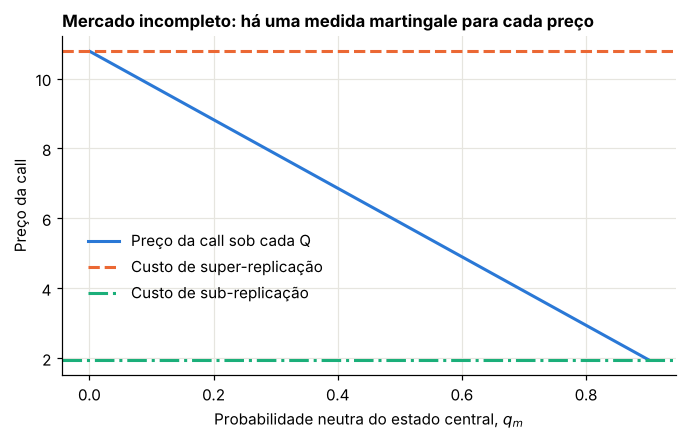

In [15]:
r9 = 0.02
Sf = np.array([120.0, 100.0, 80.0])
D2 = np.column_stack([np.full(3, 1 + r9), Sf])
p2 = np.array([1.0, 100.0])
A9 = np.maximum(Sf - 100.0, 0.0)

print("Posto de D:", np.linalg.matrix_rank(D2), "| Número de estados:", D2.shape[0])


def faixa_Q(payoff, D, p, desc):
    """Mínimo e máximo do valor descontado sob o fecho das medidas martingale."""
    m = D.shape[0]
    aeq, beq = D.T * desc, p
    bai = linprog(payoff * desc, A_eq=aeq, b_eq=beq, bounds=[(0, 1)] * m, method="highs")
    alt = linprog(-payoff * desc, A_eq=aeq, b_eq=beq, bounds=[(0, 1)] * m, method="highs")
    return bai.fun, -alt.fun, bai.x, alt.x


def super_replicacao(payoff, D, p):
    n = D.shape[1]
    r_ = linprog(p, A_ub=-D, b_ub=-payoff, bounds=[(None, None)] * n, method="highs")
    return r_.fun, r_.x


def sub_replicacao(payoff, D, p):
    n = D.shape[1]
    r_ = linprog(-p, A_ub=D, b_ub=payoff, bounds=[(None, None)] * n, method="highs")
    return -r_.fun, r_.x


desc = 1 / (1 + r9)
bx, al, Qb, Qa = faixa_Q(A9, D2, p2, desc)
sup_c, th_sup = super_replicacao(A9, D2, p2)
sub_c, th_sub = sub_replicacao(A9, D2, p2)

tabela(pd.DataFrame([
    {"Grandeza": "Mínimo sob as medidas martingale", "Valor": float(bx)},
    {"Grandeza": "Custo de sub-replicação", "Valor": float(sub_c)},
    {"Grandeza": "Máximo sob as medidas martingale", "Valor": float(al)},
    {"Grandeza": "Custo de super-replicação", "Valor": float(sup_c)},
]))

ok(np.linalg.matrix_rank(D2) < D2.shape[0], "mercado incompleto: faltam ativos")
ok(abs(al - sup_c) < 1e-8 and abs(bx - sub_c) < 1e-8, "dualidade: extremos sob Q coincidem com super e sub-replicação")
ok((D2 @ th_sup >= A9 - 1e-9).all(), "a carteira de super-replicação cobre o payoff em todo estado")

# Parametrização do segmento de medidas: q_m é o grau de liberdade
qm_grade = np.linspace(1e-3, 1.0, 400)
qu = ((1 + r9) * 100 - 80 - 20 * qm_grade) / 40
qd = 1 - qu - qm_grade
validos = (qu > 0) & (qd > 0)
grade_valida = qm_grade[validos]
preco_call = desc * 20 * qu[validos]

fig, ax = plt.subplots()
ax.plot(grade_valida, preco_call, color=AZUL, label="Preço da call sob cada Q")
ax.axhline(sup_c, color=LARANJA, ls="--", label="Custo de super-replicação")
ax.axhline(sub_c, color=VERDE, ls="-.", label="Custo de sub-replicação")
ax.set_title("Mercado incompleto: há uma medida martingale para cada preço")
ax.set_xlabel("Probabilidade neutra do estado central, $q_m$")
ax.set_ylabel("Preço da call")
ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.32))
plt.show()

### Laboratório 9.2 — Completando o mercado com uma opção negociada

Suponha agora que uma call de strike 100 seja **negociada** a um preço observado dentro do intervalo. A matriz $D$ ganha uma coluna, atinge posto 3 e a medida $Q$ passa a ser única. Agora qualquer outro direito tem preço único.

Pare um instante nessa ideia, porque ela é **a avaliação baseada em mercado em sua forma mais pura**. O mercado não escolhe $Q$ pela teoria, mas pelos preços das opções líquidas. No Módulo 1, chamamos isso de calibração.

In [16]:
preco_obs = 0.5 * (bx + al)
D3 = np.column_stack([D2, A9])
p3 = np.array([1.0, 100.0, preco_obs])

psi = np.linalg.solve(D3.T, p3)
Q3e = psi * (1 + r9)
A_novo = np.maximum(110.0 - Sf, 0.0)
theta = np.linalg.solve(D3, A_novo)
por_q = float(desc * Q3e @ A_novo)
por_carteira = float(p3 @ theta)

tabela(pd.DataFrame({"Estado": ["120", "100", "80"], "Preço de estado ψ": psi, "Q": Q3e}))
print("Put 110: pela medida", f3(por_q), "| pela carteira replicante", f3(por_carteira))
print("Sem a call negociada, a put 110 poderia estar em:", [f3(float(x)) for x in faixa_Q(A_novo, D2, p2, desc)[:2]])

ok(np.linalg.matrix_rank(D3) == 3, "com a call negociada, o mercado fica completo")
ok((Q3e > 0).all() and abs(Q3e.sum() - 1) < 1e-12, "Q é único e estritamente positivo")
ok(abs(por_q - por_carteira) < 1e-10, "preço pela medida coincide com o preço pela carteira")

,Estado,Preço de estado ψ,Q
0,120,"0,319","0,325"
1,100,"0,441","0,450"
2,80,"0,221","0,225"


Put 110: pela medida 11,029 | pela carteira replicante 11,029
Sem a call negociada, a put 110 poderia estar em: ['8,824', '13,235']
OK — com a call negociada, o mercado fica completo
OK — Q é único e estritamente positivo
OK — preço pela medida coincide com o preço pela carteira


---
## 10. Síntese

- $\Omega$ lista as histórias; uma filtração descreve como a informação chega; partições tornam tudo computável.
- Martingale é o jogo justo. Uma estratégia previsível sobre um martingale continua sendo um martingale.
- Radon-Nikodym e a fórmula de Bayes permitem trocar de medida; serão a base do Girsanov.
- Sem arbitragem existe $Q$, e $Q$ é o preço de estado normalizado.
- Direito atingível tem preço único: $A_t = \beta_t^{-1}\mathbb{E}^Q_t[\beta_T A_T]$.
- Com juros aleatórios, $\beta_T$ fica dentro da esperança.
- Mercado completo equivale a $Q$ único. Em mercado incompleto, o preço é um intervalo, e os preços das opções negociadas ajudam a fixar $Q$.

## 11. Erratas do livro neste trecho

| Local | Problema |
|---|---|
| Defs. 19 e 25 | admissibilidade com $V_t \ge -\alpha$ torna "arbitragem" qualquer estratégia alavancada com ganho esperado positivo; o correto (Harrison-Pliska) é $V_t \ge 0$ |
| Prova do Lema 1 | "$u < t$" na definição de $\psi$ deveria ser "$u > t$" |
| Prova da Prop. 1 | a soma usa $\beta_{t+1}S_{t+1}$; o correto é $\beta_{t-1}S_{t-1}$ |
| Prova da Prop. 1 | "trading strategy $\zeta \in T$" deveria ser $\phi$ |
| Nota 13 | refere "condição 3 da definição 3"; o certo é definição 1 (álgebra) |

## 12. Exercícios

**Exercício 1.** Uma partição tem 3 átomos. Quantos eventos tem a álgebra gerada? Liste-os para $\{\{a\},\{b\},\{c,d\}\}$.

<details><summary>Solução</summary>

$2^3 = 8$: $\emptyset$, $\{a\}$, $\{b\}$, $\{c,d\}$, $\{a,b\}$, $\{a,c,d\}$, $\{b,c,d\}$, $\Omega$.
</details>

**Exercício 2.** Numa árvore de dois períodos com $u = 1{,}1$, $d = 0{,}9$, $r = 2\%$, $S_0 = 100$, calcule à mão $q$ e o preço da call com $K = 100$.

<details><summary>Solução</summary>

$q = (1{,}02 - 0{,}9)/0{,}2 = 0{,}600$. Só $uu$ paga: $S_{uu} = 121$, payoff 21. Preço $= 0{,}600^2 \times 21 / 1{,}02^2 = 7{,}266$.
</details>

**Exercício 3.** Mostre que $L_t = \mathbb{E}^P_t[L]$ é martingale sob $P$.

<details><summary>Solução</summary>

Pela lei das esperanças iteradas, para $s \le t$: $\mathbb{E}^P_s[L_t] = \mathbb{E}^P_s[\mathbb{E}^P_t[L]] = \mathbb{E}^P_s[L] = L_s$.
</details>

**Exercício 4.** Num modelo de um período, suponha $d > 1+r$. Monte uma arbitragem explícita. Qual a relação com o valor de $q$?

<details><summary>Solução</summary>

Pegue 1 de título emprestado e compre o índice: valor inicial zero, e valor final $S_0(d - (1+r)) > 0$ no pior caso. Nesse caso, $q = (1 + r - d)/(u-d) < 0$: não existe probabilidade.
</details>

**Exercício 5.** No Laboratório 9.1, troque o índice por um mercado com $r = 0$. Mostre que o intervalo de preços da call com $K = 100$ vira $(0, 10)$.

<details><summary>Solução</summary>

Com $r = 0$, as condições são $q_u = q_d$ e $q_m = 1 - 2q_u$, com $q_u \in (0, 1/2)$. A call paga 20 só no estado $u$: seu preço é $20q_u \in (0, 10)$.
</details>

In [17]:
print(f"Módulo 3 concluído: {_checks['n']} verificações aprovadas.")

Módulo 3 concluído: 40 verificações aprovadas.
